# Fine-tune the final image-captioning model

**ResNet50 + Faster R-CNN + fusion + Transformer.** Start from the selected epoch-11 caption model and the same pretrained CNNs. Train on original photographs; no saved feature arrays are needed.

Open this notebook from the repository root using the environment in [inference/README.md](inference/README.md), with `pycocoevalcap==1.2` installed. **Training and preflight are off by default.**

Before running setup:

1. Extract `final_model_inference.zip` from the [model release](https://github.com/AskatQwerty/AMLNN/releases/tag/final-model-2026-11-16) under `local_artifacts/final_model/`.
2. Extract `prepared_caption_data.zip` from the [follow-up release](https://github.com/AskatQwerty/AMLNN/releases/tag/followup-experiments-2026-11-26) into the repository root. It supplies the exact saved `cache/` files; do not recreate the split or vocabulary.
3. Set `COCO_ROOT` before starting Jupyter, or edit `DATA_ROOT` below. It must contain `train2017/`, `val2017/` and `annotations/captions_train2017.json` plus `captions_val2017.json`. The default is `data/coco2017/`.
4. To resume the recorded partial run, extract `partial_finetune_resume.zip` from the follow-up release into the repository root. It restores the experiment folder containing `last.pt` and `best.pt`. Without it, the same code starts from the original selected model.

Run setup from the top. Set `RUN_PREFLIGHT=True` in Settings and rerun Settings plus the preflight cell. Check that it passes; its temporary parameter updates are discarded. Then set `RUN_PREFLIGHT=False` and `RUN_TRAINING=True`, rerun Settings and run the **five consecutive training cells** in order. Together they complete **one epoch**, with a checkpoint after each part. Repeat these same five cells for the next epoch. Resume loads `last.pt` automatically. An intentional fresh experiment should use a different `RUN_DIR`.

> **Saved local execution snapshot:** outputs below come from the original local run. Paths and launch flags were adapted for publication; this copy was syntax-checked, not rerun. Training was interrupted during epoch 1. The `KeyboardInterrupt` output is retained as evidence. The best fully validated checkpoint is still epoch 0; `last.pt` holds the partial epoch-1 update.

This is **partial joint fine-tuning**: both CNN branches and the decoder receive gradients from caption loss. Early visual blocks and the detector's box proposal/prediction heads stay fixed.

| Part | Trainable | Learning rate |
|---|---|---|
| Classification ResNet50 | `layer4` convolution weights | 0.00001 |
| Faster R-CNN | Backbone `layer4`, FPN, ROI feature head | 0.00001 |
| Fusion and Transformer | All parameters | 0.00005 |

BatchNorm statistics and affine parameters stay fixed. Detector `eval()` keeps proposal selection in inference mode; it does **not** disable gradients in the visual feature path. Box selection is detached, then final boxes are re-pooled with gradients. No detection loss or object-box labels are used.


In [1]:
# Standard libraries
import copy
import csv
import gc
import hashlib
import inspect
import json
import math
import os
import pickle
import random
import re
import time
import unicodedata
import importlib.metadata as package_metadata
from collections import Counter,defaultdict
from functools import partial
from itertools import islice
from pathlib import Path

# Images and notebook outputs
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display,Markdown
from PIL import Image,ImageOps

# Models and training
import torch
import torchvision
from torch import nn
from torch.nn import functional as F
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import Dataset,DataLoader
from torchvision import transforms
from torchvision.models import resnet50,ResNet50_Weights
from torchvision.models.detection import fasterrcnn_resnet50_fpn,FasterRCNN_ResNet50_FPN_Weights
from torchvision.ops import nms

# Caption metrics
from pycocoevalcap.bleu.bleu import Bleu
from pycocoevalcap.bleu.bleu_scorer import BleuScorer
from pycocoevalcap.cider.cider import Cider
from pycocoevalcap.cider.cider_scorer import CiderScorer


## 1. Settings

Micro batch **4**, accumulation **8**, effective batch **32** images. A mixed-orientation GPU check used about 4.03 GiB of allocated tensor memory; batch 8 was much slower under memory pressure. The final smaller group uses its actual token count. One random human caption per train image per epoch; a fixed first caption for validation loss. All human references are retained for corpus metrics.

Maximum **100 epochs**, early stopping after **3** epochs without a validation CIDEr-D improvement. Each manual cycle of five cells advances one epoch, up to these limits. Initial epoch 0 is a full-validation baseline and may remain the best checkpoint. All 113,287 train and 5,000 validation images are used. The 5,000 labeled test images are excluded from training and model selection.

Image-based fine-tuning is much slower than training on cached vectors. The run prints speed and an estimated time remaining. Changing the configuration of an existing run requires a new `RUN_DIR`.


In [2]:
PROJECT_DIR=Path.cwd()
DATA_ROOT=Path(os.environ.get("COCO_ROOT",PROJECT_DIR/"data/coco2017"))
MODEL_DIR=PROJECT_DIR/"local_artifacts/final_model/selected_model"
ENCODER_CACHE=PROJECT_DIR/"local_artifacts/final_model/encoder_cache"
torch.hub.set_dir(str(ENCODER_CACHE))
RUN_DIR=PROJECT_DIR/"experiments/final_joint_finetune_v1/resnet50_fasterrcnn_transformer_layer4_seed42"
DEVICE=torch.device("cuda" if torch.cuda.is_available() else "cpu")

RUN_PREFLIGHT=False
RUN_TRAINING=False

CONFIG={
    "seed":42,
    "micro_batch_size":4,
    "accumulation_steps":8,
    "val_batch_size":4,
    "max_epochs":100,
    "patience":3,
    "decoder_lr":5e-5,
    "resnet_lr":1e-5,
    "detector_lr":1e-5,
    "clip_norm":5.0,
    "amp":True,
    "checkpoint_minutes":5,
    "generation_beam_size":5,
    "max_steps":33,
    "unfreeze":"ResNet50 layer4; detector layer4 + FPN + ROI box head; all fusion/decoder",
    "batchnorm":"Fixed running statistics and frozen affine parameters",
    "region_selection":"Frozen RPN/predictor; detached NMS boxes; differentiable re-pooling",
    "detector_transform":"FP32, min_size=800, max_size=1333",
    "augmentation":"None; preserve the selected model's image preprocessing",
}


## 2. Load the saved split, vocabulary and human captions

Reuse the checked preparation files. Verify image IDs and previously recorded exact-duplicate groups do not cross the splits.
The prepared-data archive supplies `splits.json`, `prepared.pkl`, `text_report.json`, `vocab.json`, `image_audit.json` and `test_captions.json` under `cache/`. Setup reads these files even while training is off. Original train/validation JPEGs and caption annotations are also required; the inference archive alone is not a training dataset.


In [3]:
def load_region_prepared_data(project_dir,data_root=None):
    project_dir = Path(project_dir)
    data_root = Path(data_root) if data_root is not None else project_dir / "data" / "coco2017"
    for source in ["train2017","val2017"]:
        annotation_path = data_root / "annotations" / f"captions_{source}.json"
        if not annotation_path.is_file():
            raise FileNotFoundError(
                f"Missing {annotation_path}. Extract the shared training-data bundle beside "
                "Stage5_Starter.ipynb, or set DATA_ROOT to the bundled annotation folder. "
                "Raw train2017/val2017 JPEGs are required for region extraction."
            )
    cache = project_dir / "cache"
    required = [
        "splits.json",
        "prepared.pkl",
        "text_report.json",
        "vocab.json",
        "image_audit.json",
        "test_captions.json",
    ]
    missing = [name for name in required if not (cache / name).is_file()]
    if missing:
        raise FileNotFoundError(
            f"Missing prepared files: {missing}. Extract the shared training-data bundle into PROJECT_DIR. "
            "Do not recreate the split or vocabulary for this comparison."
        )

    # Load saved preparation results, then verify their versions agree.
    split_bytes = (cache / "splits.json").read_bytes()
    vocab_bytes = (cache / "vocab.json").read_bytes()
    prepared_bytes = (cache / "prepared.pkl").read_bytes()
    split_file = json.loads(split_bytes)
    vocab = json.loads(vocab_bytes)
    report = json.loads((cache / "text_report.json").read_text(encoding="utf-8"))
    audit = json.loads((cache / "image_audit.json").read_text(encoding="utf-8"))

    prepared_sha = hashlib.sha256(prepared_bytes).hexdigest()
    assert (
        prepared_sha == report["cache_sha256"]
    ),"Prepared caption cache changed. Rerun preparation."
    prepared = pickle.loads(
        prepared_bytes
    )  # This is our own cache, checked against its saved hash.
    del prepared_bytes

    split_ids = split_file["ids"]
    sources = split_file["feature_sources"]
    assert set(split_ids) == {"train","val","test"}
    assert sources == {
        "train": "train2017",
        "val": "val2017",
        "test": "train2017",
    },"Use the saved labeled split, not official test2017."
    payload = {"config": split_file["config"],"ids": split_ids,"feature_sources": sources}
    split_id = hashlib.sha256(
        json.dumps(payload,sort_keys=True,separators=(",",":")).encode()
    ).hexdigest()
    assert split_id == split_file["split_id"] == prepared["config"]["split_id"] == vocab["split_id"]

    source_id = split_file["config"]["source_id"]
    assert source_id == prepared["config"]["source_id"] == vocab["source_id"] == audit["source_id"]
    assert prepared["config"] == report["config"]
    assert audit["complete"] and not audit["image_errors"] and not audit["metadata_errors"]
    assert (
        prepared["token_to_id"] == vocab["token_to_id"]
        and prepared["id_to_token"] == vocab["id_to_token"]
    )
    assert vocab["token_to_id"] == {word: index for index,word in enumerate(vocab["id_to_token"])}

    ids = {
        name: vocab["token_to_id"][token]
        for name,token in [
            ("pad","<pad>"),
            ("unk","<unk>"),
            ("start","<start>"),
            ("end","<end>"),
        ]
    }
    assert len(set(ids.values())) == 4

    # One photograph and its exact duplicates must stay in one labeled split.
    sets = {name: set(values) for name,values in split_ids.items()}
    for name,values in split_ids.items():
        assert values == sorted(sets[name]) and values,f"Invalid or repeated IDs in {name}."
    for left,right in [("train","val"),("train","test"),("val","test")]:
        assert not sets[left] & sets[right],f"Image overlap: {left}/{right}."
    assert len(sets["test"]) == split_file["config"]["holdout_size"]

    owners = {
        (sources[name],image_id): name for name,values in sets.items() for image_id in values
    }
    for group in audit["pixel_duplicates"] + audit["file_duplicates"]:
        assigned = {owners[tuple(item)] for item in group if tuple(item) in owners}
        assert len(assigned) <= 1,"Exact duplicate photos cross the labeled splits."

    # Keep the original human references for evaluation.
    raw_by_source = {}
    source_image_ids = {}
    annotation_hashes = {}

    for source in ["train2017","val2017"]:
        annotation_bytes = (data_root / "annotations" / f"captions_{source}.json").read_bytes()
        annotation_hashes[source] = hashlib.sha256(annotation_bytes).hexdigest()
        annotation = json.loads(annotation_bytes)
        source_image_ids[source] = sorted(row["id"] for row in annotation["images"])
        assert len(source_image_ids[source]) == len(set(source_image_ids[source]))

        raw_by_source[source] = defaultdict(list)
        for row in annotation["annotations"]:
            assert (
                isinstance(row["caption"],str) and row["caption"].strip()
            ),"Empty human reference."
            raw_by_source[source][row["image_id"]].append(row["caption"])
        assert set(raw_by_source[source]) == set(
            source_image_ids[source]
        ),"Missing human descriptions."

        if source == "train2017":
            saved_test = json.loads((cache / "test_captions.json").read_text(encoding="utf-8"))
            assert saved_test["split_id"] == split_id
            expected_test = [
                row for row in annotation["annotations"] if row["image_id"] in sets["test"]
            ]
            assert (
                saved_test["annotations"] == expected_test
            ),"Saved test references differ from the original human captions."
        del annotation_bytes,annotation

    assert sets["train"] | sets["test"] == set(source_image_ids["train2017"])
    assert sets["val"] == set(source_image_ids["val2017"])

    references = {
        name: {image_id: raw_by_source[sources[name]][image_id] for image_id in values}
        for name,values in split_ids.items()
    }
    tokens = {name: prepared[f"{name}_tokens"] for name in split_ids}
    for name,values in tokens.items():
        assert sorted(values) == split_ids[name]
        assert all(
            rows and all(row for row in rows) for rows in values.values()
        ),"Empty tokenized caption."
        if name != "train":
            assert all(
                len(rows) == len(references[name][image_id]) for image_id,rows in values.items()
            ),"Evaluation references were dropped."

    # Test and validation captions must not contribute to the vocabulary.
    train_counts = Counter(
        token for rows in tokens["train"].values() for row in rows for token in row
    )
    assert train_counts == prepared["train_counts"]
    settings = prepared["config"]["settings"]
    regular = [
        token
        for token,count in sorted(train_counts.items(),key=lambda row: (-row[1],row[0]))
        if count >= settings["min_frequency"]
    ][: settings["max_vocab_tokens"]]
    assert (
        vocab["id_to_token"] == settings["special_tokens"] + regular
    ),"Vocabulary must be fitted on training captions only."

    data = {
        "project_dir": project_dir,
        "data_root": data_root,
        "split_ids": split_ids,
        "feature_sources": sources,
        "tokens": tokens,
        "references": references,
        "source_image_ids": source_image_ids,
        "token_to_id": vocab["token_to_id"],
        "id_to_token": vocab["id_to_token"],
        "ids": ids,
        "max_content_tokens": prepared["config"]["max_content_tokens"],
        "text_settings": settings,
        "provenance": {
            "source_id": source_id,
            "split_id": split_id,
            "prepared_sha256": prepared_sha,
            "vocab_sha256": hashlib.sha256(vocab_bytes).hexdigest(),
            "splits_sha256": hashlib.sha256(split_bytes).hexdigest(),
            "annotations_sha256": annotation_hashes,
        },
    }

    print(
        "Verified disjoint labeled splits:",
        {name: len(values) for name,values in split_ids.items()},
    )
    print("Vocabulary:",len(data["id_to_token"]),"| special IDs:",ids)
    return data

In [4]:
class MetricEvaluator:
    def __init__(self,settings):
        version = package_metadata.version("pycocoevalcap")
        if version != "1.2":
            raise RuntimeError("Use pycocoevalcap==1.2 so all experiments use the same scorers.")
        self.token_pattern = settings["token_pattern"]
        re.compile(self.token_pattern)
        self.metadata = {
            "package": "pycocoevalcap",
            "version": version,
            "bleu": {
                "implementation": "Bleu(4)",
                "aggregation": "corpus",
                "scale": "0..1; no multiplication by 100",
            },
            "cider_d": {
                "implementation": "Cider(n=4,sigma=6.0)",
                "ngrams": 4,
                "sigma": 6.0,
                "scale": "native score, including the implementation's factor 10; no extra multiplication",
                "document_frequency": "all reference sets in the evaluated split",
            },
            "tokenization": {
                "name": "project_regex_v1",
                "normalization": "NFKC,lowercase,smart quotes,whitespace",
                "token_pattern": self.token_pattern,
                "reference_vocabulary_mapping": False,
                "note": "Same tokenizer for predictions and raw references; not COCO leaderboard PTB tokenization.",
            },
            "source_sha256": {
                name: hashlib.sha256(Path(inspect.getfile(cls)).read_bytes()).hexdigest()
                for name,cls in [
                    ("bleu",Bleu),
                    ("bleu_scorer",BleuScorer),
                    ("cider",Cider),
                    ("cider_scorer",CiderScorer),
                ]
            },
        }

    def tokenize(self,text):
        text = unicodedata.normalize("NFKC",text).lower()
        text = text.translate(
            str.maketrans(
                {
                    "\u2018": "'",
                    "\u2019": "'",
                    "\u02bc": "'",
                    "\u201c": '"',
                    "\u201d": '"',
                    "\u200b": " ",
                    "\ufeff": " ",
                }
            )
        )
        text = " ".join(text.split())
        return " ".join(re.findall(self.token_pattern,text))

    def score(self,records,expected_ids=None):
        # One corpus call is essential: averaging batch BLEU/CIDEr is incorrect.
        if len(records) < 2:
            raise ValueError("CIDEr-D needs a corpus with at least two images.")
        gts = {}
        res = {}
        for item in records:
            image_id = int(item["image_id"])
            if image_id in gts:
                raise ValueError(f"Duplicate prediction for image {image_id}")
            references = item["references"]
            if not isinstance(references,list) or not references:
                raise ValueError(f"Missing human references for image {image_id}")
            if not all(isinstance(text,str) and text.strip() for text in references):
                raise ValueError(f"Empty or invalid human reference for image {image_id}")
            if not isinstance(item["prediction"],str):
                raise TypeError("Each prediction must be a string.")
            gts[image_id] = [self.tokenize(text) for text in references]
            if not all(gts[image_id]):
                raise ValueError(f"A reference has no tokens for image {image_id}")
            res[image_id] = [self.tokenize(item["prediction"])]
        if expected_ids is not None:
            expected = [int(image_id) for image_id in expected_ids]
            if len(expected) != len(set(expected)) or set(gts) != set(expected):
                raise ValueError("Predictions do not cover exactly the requested evaluation split.")
        bleu,_ = Bleu(4).compute_score(gts,res,verbose=0)
        cider_d,_ = Cider(n=4,sigma=6.0).compute_score(gts,res)
        scores = {"bleu1": float(bleu[0]),"bleu4": float(bleu[3]),"cider_d": float(cider_d)}
        if not all(np.isfinite(value) for value in scores.values()):
            raise ValueError("The metric implementation returned a non-finite score.")
        return scores


def check_metrics(evaluator):
    # Distinct documents keep CIDEr's corpus IDF meaningful in this small check.
    sentences = [
        "A red bus drives down the road.",
        "Two cats sleep on the green sofa.",
        "A woman holds a yellow umbrella.",
    ]
    records = [
        {"image_id": index,"prediction": text,"references": [text,text]}
        for index,text in enumerate(sentences)
    ]
    exact = evaluator.score(records,expected_ids=range(len(records)))
    assert abs(exact["bleu1"] - 1) < 1e-6 and abs(exact["bleu4"] - 1) < 1e-6
    assert abs(exact["cider_d"] - 10) < 1e-6
    unrelated = [
        {**row,"prediction": "unrelated vocabulary never matches anything"} for row in records
    ]
    poor = evaluator.score(unrelated)
    assert poor["bleu1"] < 1e-6 and poor["bleu4"] < 1e-6 and poor["cider_d"] == 0
    empty = evaluator.score([{**row,"prediction": ""} for row in records])
    assert empty["cider_d"] == 0 and empty["bleu1"] < 1e-6
    # These are library corpus scores, not sentence scores averaged by our code.
    gts = {
        row["image_id"]: [evaluator.tokenize(text) for text in row["references"]] for row in records
    }
    res = {row["image_id"]: [evaluator.tokenize(row["prediction"])] for row in records}
    direct_bleu,_ = Bleu(4).compute_score(gts,res,verbose=0)
    direct_cider,_ = Cider(n=4,sigma=6.0).compute_score(gts,res)
    assert exact == {
        "bleu1": float(direct_bleu[0]),
        "bleu4": float(direct_bleu[3]),
        "cider_d": float(direct_cider),
    }
    try:
        evaluator.score(records,expected_ids=[0,1,99])
    except ValueError:
        pass
    else:
        raise AssertionError("Incomplete evaluation corpus was accepted.")
    print(
        "Metric checks passed: exact captions, wrong captions, empty predictions and full-corpus coverage."
    )
    return {"exact": exact,"unrelated": poor,"empty_predictions": empty}

In [5]:
data=load_region_prepared_data(PROJECT_DIR,DATA_ROOT)
evaluator=MetricEvaluator(data["text_settings"])
PAD_ID=data["ids"]["pad"]
UNK_ID=data["ids"]["unk"]
START_ID=data["ids"]["start"]
END_ID=data["ids"]["end"]
id_to_token=data["id_to_token"]

CONFIG.update(
    train_image_count=len(data["split_ids"]["train"]),
    validation_image_count=len(data["split_ids"]["val"]),
    provenance=data["provenance"],
    selected_model_sha256=hashlib.sha256((MODEL_DIR/"weights.pt").read_bytes()).hexdigest(),
    metrics=evaluator.metadata,
    implementation_sha256="0b7d0f1b845d1f3d577b05fd5d62c62f54bd858dc3b60823136b69f9c5d324d5",
)
print("Device:",torch.cuda.get_device_name(DEVICE) if DEVICE.type=="cuda" else DEVICE)
print("Effective batch:",CONFIG["micro_batch_size"]*CONFIG["accumulation_steps"])
print("Checkpoint folder:",RUN_DIR)


Verified disjoint labeled splits: {'train': 113287, 'val': 5000, 'test': 5000}
Vocabulary: 10004 | special IDs: {'pad': 0, 'unk': 1, 'start': 2, 'end': 3}
Device: NVIDIA GeForce RTX 4060 Laptop GPU
Effective batch: 32
Checkpoint folder: C:\Users\askat\Study\3.1\AML Applied Machine Learning\Final\experiments\final_joint_finetune_v1\resnet50_fasterrcnn_transformer_layer4_seed42


In [6]:
class PhotoCaptionDataset(Dataset):
    def __init__(self,split,epoch,start_index=0):
        assert split in ("train","val")
        self.split=split
        image_ids=sorted(data["split_ids"][split])
        caption_rng=random.Random(CONFIG["seed"]+epoch)
        self.choices={image_id:caption_rng.randrange(len(data["tokens"][split][image_id]))
                      if split=="train" else 0 for image_id in image_ids}
        if split=="train":
            random.Random(CONFIG["seed"]+epoch).shuffle(image_ids)
        self.image_ids=image_ids[start_index:]
        self.normalize=transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self,index):
        image_id=self.image_ids[index]
        source=data["feature_sources"][self.split]
        path=DATA_ROOT/source/f"{image_id:012d}.jpg"
        with Image.open(path) as image:
            rgb=ImageOps.exif_transpose(image).convert("RGB")
            padded=ImageOps.pad(rgb,(224,224),method=Image.Resampling.BILINEAR,
                                color=(124,116,104),centering=(0.5,0.5))
            grid_image=self.normalize(transforms.ToTensor()(padded))
            detector_image=transforms.ToTensor()(rgb)

        words=data["tokens"][self.split][image_id][self.choices[image_id]][:32]
        caption=[START_ID]+[data["token_to_id"].get(word,UNK_ID) for word in words]+[END_ID]
        return {"grid_image":grid_image,"detector_image":detector_image,
                "caption":torch.tensor(caption,dtype=torch.long),"image_id":image_id,
                "references":data["references"][self.split][image_id]}


def photo_collate(items):
    return {
        "grid_images":torch.stack([row["grid_image"] for row in items]),
        "detector_images":[row["detector_image"] for row in items],
        "captions":pad_sequence([row["caption"] for row in items],batch_first=True,padding_value=PAD_ID),
        "image_ids":[row["image_id"] for row in items],
        "references":[row["references"] for row in items],
    }


def get_loader(split,epoch,start_index=0,batch_size=None):
    dataset=PhotoCaptionDataset(split,epoch,start_index)
    batch_size=batch_size or CONFIG["micro_batch_size" if split=="train" else "val_batch_size"]
    return DataLoader(dataset,batch_size=batch_size,shuffle=False,num_workers=0,
                      collate_fn=photo_collate,pin_memory=DEVICE.type=="cuda",
                      generator=torch.Generator().manual_seed(CONFIG["seed"]+epoch))


def score_captions(predictions,references):
    records=[{"image_id":index,"prediction":caption,"references":refs}
             for index,(caption,refs) in enumerate(zip(predictions,references))]
    assert len(predictions)==len(references)
    scores=evaluator.score(records,expected_ids=range(len(records)))
    return {"CIDEr-D":scores["cider_d"],"BLEU-1":scores["bleu1"],"BLEU-4":scores["bleu4"]}

Input: <start> a woman and her surf board stand on a beach
Target: a woman and her surf board stand on a beach <end>


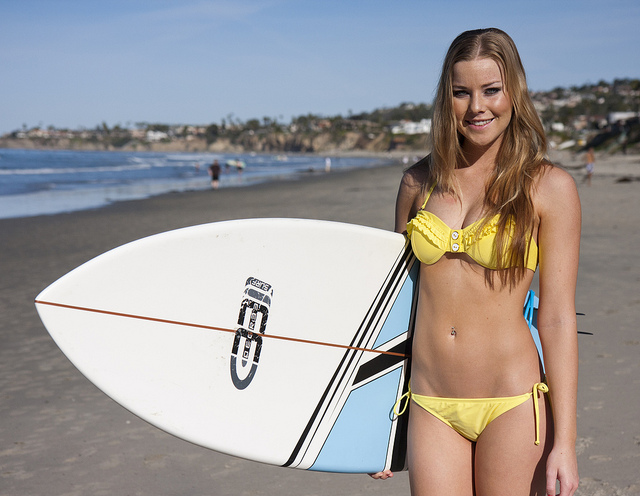

Human caption: The girl holds her surfboard on the sand.


In [7]:
sample=PhotoCaptionDataset("train",epoch=1)[0]
caption=sample["caption"].tolist()
print("Input:"," ".join(id_to_token[token] for token in caption[:-1]))
print("Target:"," ".join(id_to_token[token] for token in caption[1:]))
display(transforms.ToPILImage()(sample["detector_image"]))
print("Human caption:",sample["references"][0])
del sample


## 3. The saved decoder and differentiable CNN features

ResNet50 produces 49 grid vectors and one global prefix. Faster R-CNN produces up to 36 region vectors plus their boxes and mask. Fusion projections and the three-layer Transformer remain the same as in the selected model.

ResNet50 uses 224x224 resize + padding. The detector uses its original aspect ratio and 800/1333 resize. CNN features are recomputed as the weights change; storing a fixed feature cache would prevent this fine-tuning.


In [8]:
class GatedCrossAttentionLayer(nn.TransformerDecoderLayer):
    """A decoder block whose new visual residual can start at zero."""

    def __init__(self,d_model,nhead,dim_feedforward,dropout):
        super().__init__(
            d_model=d_model,nhead=nhead,dim_feedforward=dim_feedforward,
            dropout=dropout,activation="relu",batch_first=True,norm_first=True,
        )
        self.cross_gate = nn.Parameter(torch.zeros(()))

    def forward(self,tokens,memory,causal_mask,text_padding_mask,memory_padding_mask):
        query = self.norm1(tokens)
        attended,_ = self.self_attn(
            query,query,query,attn_mask=causal_mask,
            key_padding_mask=text_padding_mask,need_weights=False,
        )
        tokens = tokens + self.dropout1(attended)

        # With gate=0, the copied image-prefix model is unchanged in eval mode.
        # The gate receives gradients immediately; the new branch learns as it opens.
        attended,_ = self.multihead_attn(
            self.norm2(tokens),memory,memory,
            key_padding_mask=memory_padding_mask,need_weights=False,
        )
        tokens = tokens + torch.tanh(self.cross_gate) * self.dropout2(attended)
        hidden = self.linear2(self.dropout(self.activation(self.linear1(self.norm3(tokens)))))
        return tokens + self.dropout3(hidden)


class FusionCaptionTransformer(nn.Module):
    """Frozen CNN vectors in, trainable visual fusion and caption decoder out."""

    def __init__(
        self,vocab_size,pad_id,grid_feature_dim=2048,region_feature_dim=1024,
        d_model=512,num_layers=3,nhead=8,dim_feedforward=2048,
        dropout=0.3,grid_size=7,max_regions=36,max_positions=34,
    ):
        super().__init__()
        if d_model % nhead or min(num_layers,grid_size,max_regions) < 1:
            raise ValueError("Invalid decoder width, layer count or visual layout.")
        if max_positions < 2:
            raise ValueError("Positions must accommodate the image prefix and a word.")
        self.decoder_type = "transformer_fusion"
        self.d_model = self.hidden_size = d_model
        self.num_layers = num_layers
        self.pad_id = pad_id
        self.grid_size,self.max_regions = grid_size,max_regions
        self.max_positions = max_positions

        # Keep the trained global prefix. Averaging uses the cached ResNet50 grid.
        self.image_projection = nn.Linear(grid_feature_dim,d_model)
        self.embedding = nn.Embedding(vocab_size,d_model,padding_idx=pad_id)
        self.position_embedding = nn.Embedding(max_positions,d_model)
        self.embedding_dropout = nn.Dropout(dropout)
        self.layers = nn.ModuleList([
            GatedCrossAttentionLayer(d_model,nhead,dim_feedforward,dropout)
            for _ in range(num_layers)
        ])
        self.final_norm = nn.LayerNorm(d_model)
        self.output_dropout = nn.Dropout(dropout)
        self.output = nn.Linear(d_model,vocab_size)

        # Fusion keeps all visual tokens; cross-attention learns how to use them.
        self.grid_projection = nn.Linear(grid_feature_dim,d_model)
        self.region_projection = nn.Linear(region_feature_dim,d_model)
        self.grid_norm = nn.LayerNorm(d_model)
        self.region_norm = nn.LayerNorm(d_model)
        self.row_embedding = nn.Embedding(grid_size,d_model)
        self.column_embedding = nn.Embedding(grid_size,d_model)
        self.source_embedding = nn.Embedding(2,d_model)
        self.region_box_projection = nn.Linear(4,d_model)

        for embedding in [self.embedding,self.position_embedding,self.row_embedding,
                          self.column_embedding,self.source_embedding]:
            nn.init.normal_(embedding.weight,mean=0,std=0.02)
        with torch.no_grad():
            self.embedding.weight[pad_id].zero_()

    def prepare_memory(self,grid_features,region_features,region_mask,region_boxes=None,global_features=None):
        if grid_features.ndim != 3 or grid_features.shape[1:] != (
            self.grid_size ** 2,self.image_projection.in_features
        ):
            raise ValueError("Expected ResNet50 features [B,49,2048].")
        if region_features.ndim != 3 or len(region_features) != len(grid_features):
            raise ValueError("Expected region features [B,K,1024] for the same images.")
        if not 1 <= region_features.shape[1] <= self.max_regions:
            raise ValueError("The number of ROI slots is outside the configured range.")
        if region_features.shape[2] != self.region_projection.in_features:
            raise ValueError("Unexpected region feature dimension.")
        if region_mask.dtype != torch.bool or region_mask.shape != region_features.shape[:2]:
            raise ValueError("region_mask must be bool[B,K], True for valid regions.")
        region_mask = region_mask.to(grid_features.device)
        if not region_mask.any(dim=1).all():
            raise ValueError("Each image needs a valid ROI, including an extraction fallback.")
        if region_boxes is None:
            raise ValueError("Pass cached normalized xyxy boxes [B,K,4].")
        if region_boxes.shape != (*region_features.shape[:2],4):
            raise ValueError("Expected normalized xyxy boxes [B,K,4].")

        # Ignore padded garbage before it reaches any trainable operation.
        clean_regions = region_features.masked_fill(~region_mask.unsqueeze(-1),0)
        clean_boxes = region_boxes.masked_fill(~region_mask.unsqueeze(-1),0)
        grid = self.grid_norm(self.grid_projection(grid_features))
        positions = torch.arange(self.grid_size ** 2,device=grid_features.device)
        grid_positions = self.row_embedding(positions // self.grid_size)
        grid_positions = grid_positions + self.column_embedding(positions % self.grid_size)
        grid = grid + grid_positions.unsqueeze(0) + self.source_embedding.weight[0]
        regions = self.region_norm(self.region_projection(clean_regions))
        regions = regions + self.region_box_projection(clean_boxes) + self.source_embedding.weight[1]
        regions = regions.masked_fill(~region_mask.unsqueeze(-1),0)

        memory = torch.cat([grid,regions],dim=1)
        grid_is_padding = torch.zeros(grid.shape[:2],dtype=torch.bool,device=grid.device)
        memory_padding_mask = torch.cat([grid_is_padding,~region_mask],dim=1)
        if global_features is None:
            global_features = grid_features.mean(dim=1)
        elif global_features.shape != (len(grid_features),self.image_projection.in_features):
            raise ValueError("Expected cached global ResNet50 vectors [B,2048].")
        image_token = self.image_projection(global_features).unsqueeze(1)
        return memory,memory_padding_mask,image_token

    def decode_memory(self,memory,memory_padding_mask,image_token,input_ids):
        if input_ids.ndim != 2 or len(input_ids) != len(memory) or input_ids.shape[1] < 1:
            raise ValueError("Each image needs a nonempty word sequence.")
        length = input_ids.shape[1] + 1
        if length > self.max_positions:
            raise ValueError("The image prefix and input words exceed the learned positions.")
        words = self.embedding(input_ids) * self.d_model ** 0.5
        tokens = torch.cat([image_token,words],dim=1)
        positions = torch.arange(length,device=input_ids.device)
        tokens = self.embedding_dropout(tokens + self.position_embedding(positions).unsqueeze(0))
        causal = torch.triu(torch.ones(length,length,dtype=torch.bool,device=tokens.device),1)
        image_is_padding = torch.zeros(len(input_ids),1,dtype=torch.bool,device=tokens.device)
        text_padding = torch.cat([image_is_padding,input_ids.eq(self.pad_id)],dim=1)
        for layer in self.layers:
            tokens = layer(tokens,memory,causal,text_padding,memory_padding_mask)
        return self.output(self.output_dropout(self.final_norm(tokens[:,1:])))

    def forward(self,grid_features,region_features,input_ids,region_mask,region_boxes=None,global_features=None):
        memory,padding,image_token = self.prepare_memory(
            grid_features,region_features,region_mask,region_boxes,global_features
        )
        return self.decode_memory(memory,padding,image_token,input_ids)

    @torch.no_grad()
    def greedy(
        self,grid_features,region_features,start_id,end_id,max_steps=33,
        region_mask=None,region_boxes=None,global_features=None,
    ):
        if not 1 <= max_steps < self.max_positions:
            raise ValueError("Generation must fit the image prefix and learned text positions.")
        was_training = self.training
        self.eval()
        try:
            memory,padding,image_token = self.prepare_memory(
                grid_features,region_features,region_mask,region_boxes,global_features
            )
            prefix = torch.full((len(grid_features),1),start_id,dtype=torch.long,
                                device=grid_features.device)
            finished = torch.zeros(len(prefix),dtype=torch.bool,device=prefix.device)
            predictions = [[] for _ in range(len(prefix))]
            for _ in range(max_steps):
                logits = self.decode_memory(memory,padding,image_token,prefix)[:,-1]
                logits[:,self.pad_id] = -torch.inf
                logits[:,start_id] = -torch.inf
                next_ids = logits.argmax(dim=-1)
                for index,(token_id,done) in enumerate(zip(next_ids.tolist(),finished.tolist())):
                    if not done and token_id != end_id:
                        predictions[index].append(token_id)
                finished |= next_ids.eq(end_id)
                if finished.all():
                    break
                prefix = torch.cat([prefix,next_ids.unsqueeze(1)],dim=1)
            return predictions
        finally:
            self.train(was_training)

    def cross_gate_values(self):
        return [float(torch.tanh(layer.cross_gate.detach()).cpu()) for layer in self.layers]

In [9]:
REGION_TORCH_PIN = "2.13.0"


REGION_TORCHVISION_PIN = "0.28.0"


REGION_WEIGHT_NAME = "FasterRCNN_ResNet50_FPN_Weights.COCO_V1"


REGION_CACHE_VERSION = "fasterrcnn_resnet50_fpn_coco_v1_regions_v1"


REGION_DIM = 1024


def region_feature_contract(max_regions=36,score_threshold=0.2,nms_iou=0.5):
    return {
        "version": REGION_CACHE_VERSION,
        "detector": "torchvision.models.detection.fasterrcnn_resnet50_fpn",
        "weights": REGION_WEIGHT_NAME,
        "torch": REGION_TORCH_PIN,
        "torchvision": REGION_TORCHVISION_PIN,
        "input": "EXIF-transposed RGB; ToTensor float32 in [0,1]; original aspect ratio and size",
        "detector_transform": {
            "min_size": 800,"max_size": 1333,"size_divisible": 32,
            "image_mean": [0.485,0.456,0.406],"image_std": [0.229,0.224,0.225],
        },
        "compute_dtype": "float32; autocast disabled",
        "cnn_frozen": True,
        "detector_eval": True,
        "detector_score_threshold": 0.05,
        "detector_class_nms_iou": 0.5,
        "detector_max_detections": 100,
        "rpn_pre_nms_top_n_test": 1000,
        "rpn_post_nms_top_n_test": 1000,
        "rpn_nms_iou": 0.7,
        "selection": "Final class-NMS detections, score filter, class-agnostic NMS, descending score, top K",
        "score_threshold": float(score_threshold),
        "class_agnostic_nms_iou": float(nms_iou),
        "max_regions": int(max_regions),
        "feature_dimension": REGION_DIM,
        "feature_layer": "box_roi_pool + TwoMLPHead.fc6/ReLU/fc7/ReLU, rerun on selected FINAL boxes",
        "feature_storage_dtype": "float16 after finite/overflow validation; compute and returned features remain float32",
        "boxes": "xyxy in original EXIF-transposed RGB pixel coordinates; zero padding",
        "boxes_normalized": "xyxy divided by original [width,height,width,height]; reporting only",
        "mask": "bool; True means a real selected region, including the full-image fallback",
        "padding": "zero features/boxes/scores, label=-1, mask=False",
        "fallback": "If no boxes remain, ROI-pool the full transformed image; valid count=1, score=0, label=-1, fallback=True",
        "decoder_inputs": "visual features and valid-region mask only; no predicted class labels, scores or object words",
        "test_exposure_note": "COCO detector pretraining may include train2017 images used by the captioning holdout; do not claim an unseen-image encoder test.",
    }


def build_frozen_region_detector(device="cpu",allow_download=False):
    """No model is constructed or downloaded until this function is explicitly called."""
    if torch.__version__.split("+")[0] != REGION_TORCH_PIN or torchvision.__version__.split("+")[0] != REGION_TORCHVISION_PIN:
        raise RuntimeError(f"Use torch=={REGION_TORCH_PIN} and torchvision=={REGION_TORCHVISION_PIN} for this pinned region contract.")
    weights = FasterRCNN_ResNet50_FPN_Weights.COCO_V1
    filename = weights.url.rsplit("/",1)[-1]
    checkpoint = Path(torch.hub.get_dir()) / "checkpoints" / filename
    if not checkpoint.is_file() and not allow_download:
        raise FileNotFoundError(f"Missing {checkpoint}. Downloading is disabled; set allow_download=True only when ready to obtain the pretrained detector.")
    if checkpoint.is_file():
        digest = hashlib.sha256(checkpoint.read_bytes()).hexdigest()
        assert digest.startswith("258fb6c6"),"Cached detector weights do not match COCO_V1."
    detector = fasterrcnn_resnet50_fpn(
        weights=weights,weights_backbone=None,progress=True,
        min_size=800,max_size=1333,
        box_score_thresh=0.05,box_nms_thresh=0.5,box_detections_per_img=100,
        rpn_pre_nms_top_n_test=1000,rpn_post_nms_top_n_test=1000,rpn_nms_thresh=0.7,
    )
    detector = detector.to(device=torch.device(device),dtype=torch.float32).requires_grad_(False).eval()
    assert detector.roi_heads.box_head.fc7.out_features == REGION_DIM
    digest = hashlib.sha256(checkpoint.read_bytes()).hexdigest()
    assert digest.startswith("258fb6c6")
    detector.region_feature_metadata = {**region_feature_contract(),"weights_sha256": digest,
                                        "device": str(torch.device(device))}
    return detector


def _select_region_boxes(detection,transformed_size,max_regions,score_threshold,nms_iou):
    boxes,scores,labels = detection["boxes"],detection["scores"],detection["labels"]
    assert boxes.ndim == 2 and boxes.shape[1] == 4
    assert scores.shape == labels.shape == (len(boxes),)
    assert torch.isfinite(boxes).all() and torch.isfinite(scores).all()
    assert torch.all((scores >= 0) & (scores <= 1))
    if len(boxes):
        assert torch.all(boxes[:,2:] > boxes[:,:2]) and torch.all(labels > 0)
    keep = scores >= score_threshold
    boxes,scores,labels = boxes[keep],scores[keep],labels[keep]
    if len(boxes):
        order = torch.argsort(scores,descending=True,stable=True)
        boxes,scores,labels = boxes[order],scores[order],labels[order]
        keep = nms(boxes,scores,nms_iou)[:max_regions]
        return {"boxes": boxes[keep],"scores": scores[keep],"labels": labels[keep],"fallback": False}
    height,width = transformed_size
    return {
        "boxes": boxes.new_tensor([[0,0,width,height]]),
        "scores": scores.new_zeros(1),
        "labels": torch.full((1,),-1,dtype=torch.long,device=boxes.device),
        "fallback": True,
    }

In [10]:
FUSION_RESNET50_SHA256 = "11ad3fa62ca79e40addfd354a8ec4b7c75143b3038b8d2a807fbc68deab379ca"


FUSION_DETECTOR_SHA256 = "258fb6c638b15964ddcdd1ae0748c5eef1be9e732750120cc857feed3faac384"


def _inference_file_hash(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda:stream.read(8 * 1024 * 1024),b""):
            digest.update(block)
    return digest.hexdigest()


def build_frozen_fusion_encoders(device,project_dir=None,allow_download=False):
    """Load the two fixed encoders only when explicitly called."""
    device = torch.device(device)
    project_dir = Path.cwd() if project_dir is None else Path(project_dir)
    weights = ResNet50_Weights.IMAGENET1K_V2
    filename = weights.url.rsplit("/",1)[-1]
    candidates = [
        project_dir / "cache" / "models" / "checkpoints" / filename,
        Path(torch.hub.get_dir()) / "checkpoints" / filename,
        Path.home() / ".cache" / "torch" / "hub" / "checkpoints" / filename,
    ]
    weight_path = next((path for path in candidates if path.is_file()),None)
    if weight_path is None:
        if not allow_download:
            raise FileNotFoundError(
                f"Cached {filename} is missing. Supply the project's cached weights; "
                "downloads are disabled unless allow_download=True is explicitly set."
            )
        weights.get_state_dict(progress=True,check_hash=True)
        weight_path = Path(torch.hub.get_dir()) / "checkpoints" / filename
    if _inference_file_hash(weight_path) != FUSION_RESNET50_SHA256:
        raise ValueError("ResNet50 weights differ from the training feature cache.")

    backbone = resnet50(weights=None)
    backbone.load_state_dict(torch.load(weight_path,map_location="cpu",weights_only=True),strict=True)
    grid_encoder = nn.Sequential(*list(backbone.children())[:-2]).requires_grad_(False).to(device).eval()
    # Use the original pooling module on its feature map, before cache rounding.
    global_pool = backbone.avgpool.requires_grad_(False).to(device).eval()
    del backbone
    detector = build_frozen_region_detector(device,allow_download=allow_download)
    if detector.region_feature_metadata["weights_sha256"] != FUSION_DETECTOR_SHA256:
        raise ValueError("Faster R-CNN weights differ from the training region cache.")
    assert not any(parameter.requires_grad for parameter in grid_encoder.parameters())
    assert not any(parameter.requires_grad for parameter in detector.parameters())
    actual_device = next(grid_encoder.parameters()).device
    metadata = {
        "resnet50_weights":"ResNet50_Weights.IMAGENET1K_V2",
        "resnet50_weights_sha256":FUSION_RESNET50_SHA256,
        "resnet50_image":"EXIF transpose, RGB, ImageOps.pad224x224 BILINEAR, centered",
        "padding_color":[124,116,104],
        "normalization":{"mean":[0.485,0.456,0.406],"std":[0.229,0.224,0.225]},
        "resnet50_compute":"CUDA autocast float16" if actual_device.type == "cuda" else "CPU float32 fallback",
        "grid":"layer4 NCHW -> flatten spatial dimensions -> [B,49,2048]; float16 round then float32",
        "global":"AdaptiveAvgPool2d on the feature map inside the same autocast forward, before grid storage rounding; float32 result",
        "detector":dict(detector.region_feature_metadata),
        "regions":"Original RGB float32[0,1]; detector FP32; selected final-box ROI vectors float16 round then float32",
        "region_settings":region_feature_contract(36,0.2,0.5),
        "cnn_frozen":True,"device":str(actual_device),
        "precision_note":"The preprocessing and storage rounding match training. CPU fallback and different GPU batch/kernel paths can produce small numerical differences.",
    }
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
    ])
    return {"grid_encoder":grid_encoder,"global_pool":global_pool,"detector":detector,
            "resnet_transform":transform,"device":actual_device,"metadata":metadata}

In [11]:
def file_sha256(path):
    digest=hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda:stream.read(8*1024**2),b''):
            digest.update(block)
    return digest.hexdigest()


def load_final_model(model_dir,device):
    model_dir=Path(model_dir)
    inference=json.loads((model_dir/'inference_config.json').read_text(encoding='utf-8'))
    vocabulary=json.loads((model_dir/'vocabulary.json').read_text(encoding='utf-8'))
    source=json.loads((model_dir/'source_run_config.json').read_text(encoding='utf-8'))
    config=source['config']

    # Historical snapshot paths in the metadata are provenance, not dependencies.
    weights_path=model_dir/'weights.pt'
    actual_sha=file_sha256(weights_path)
    if actual_sha!=inference['weights_sha256']:
        raise ValueError('The final model weights do not match inference_config.json.')
    if file_sha256(model_dir/'vocabulary.json')!=inference['vocabulary_sha256']:
        raise ValueError('The saved vocabulary differs from the final model vocabulary.')
    if file_sha256(model_dir/'source_run_config.json')!=inference['source_run_config_sha256']:
        raise ValueError('The model architecture configuration differs from the saved run.')

    token_ids={name:vocabulary['token_to_id'][f'<{name}>'] for name in ['pad','unk','start','end']}
    model=FusionCaptionTransformer(
        vocab_size=len(vocabulary['id_to_token']),pad_id=token_ids['pad'],
        grid_feature_dim=config['grid_feature_dim'],region_feature_dim=config['region_feature_dim'],
        d_model=config['d_model'],num_layers=config['num_layers'],nhead=config['nhead'],
        dim_feedforward=config['dim_feedforward'],dropout=config['dropout'],
        grid_size=config['grid_size'],max_regions=config['max_regions'],max_positions=34,
    )
    state=torch.load(weights_path,map_location='cpu',weights_only=True)
    model.load_state_dict(state,strict=True)
    model=model.to(device).requires_grad_(False).eval()
    return model,vocabulary,token_ids,inference,actual_sha

In [12]:
class TrainableVisualEncoder(nn.Module):
    """Train the last CNN blocks, FPN and ROI feature head from caption loss."""

    def __init__(self,encoders,max_regions=36,amp=True):
        super().__init__()
        self.grid_encoder=encoders["grid_encoder"]
        self.global_pool=encoders["global_pool"]
        self.detector=encoders["detector"]
        self.max_regions=max_regions
        self.amp=amp
        self.original_feature_metadata=encoders["metadata"]

        # Preserve early visual filters and detection proposal/prediction heads.
        self.requires_grad_(False)
        self.grid_encoder[-1].requires_grad_(True)
        self.detector.backbone.body.layer4.requires_grad_(True)
        self.detector.backbone.fpn.requires_grad_(True)
        self.detector.roi_heads.box_head.requires_grad_(True)

        # Tiny image batches are unsuitable for updating BatchNorm statistics.
        for module in self.modules():
            if isinstance(module,nn.modules.batchnorm._BatchNorm):
                module.requires_grad_(False)
        self.train(True)

    def train(self,mode=True):
        super().train(mode)
        # eval() changes detector behavior, but does not disable its gradients.
        self.detector.eval()
        for module in self.modules():
            if isinstance(module,nn.modules.batchnorm._BatchNorm):
                module.eval()
        return self

    def trainable_parameter_groups(self):
        return {
            "resnet50":[p for p in self.grid_encoder.parameters() if p.requires_grad],
            "detector":[p for p in self.detector.parameters() if p.requires_grad],
        }

    def forward(self,grid_images,detector_images):
        """Accept normalized 224x224 images and original RGB tensors in [0,1]."""
        device=next(self.grid_encoder.parameters()).device
        grid_images=grid_images.to(device,non_blocking=True)
        rgb_images=[image.to(device=device,dtype=torch.float32,non_blocking=True)
                    for image in detector_images]
        assert len(grid_images)==len(rgb_images)>0
        assert grid_images.shape[1:]==(3,224,224)

        # Keep the selected model's classification-image preprocessing/precision.
        with torch.autocast(device_type=device.type,dtype=torch.float16,enabled=self.amp and device.type=="cuda"):
            feature_map=self.grid_encoder(grid_images)
            global_features=self.global_pool(feature_map).flatten(1)
        grid=feature_map.flatten(2).transpose(1,2).contiguous().to(torch.float16).float()
        global_features=global_features.float()

        # The detector remains FP32. Only box selection is outside autograd.
        with torch.autocast(device_type=device.type,enabled=False):
            transformed,_=self.detector.transform(rgb_images,None)
            fpn_features=self.detector.backbone(transformed.tensors)
            if isinstance(fpn_features,torch.Tensor):
                fpn_features={"0":fpn_features}

            # No caption gradient through NMS, box coordinates or object labels.
            with torch.no_grad():
                detached_features={name:value.detach() for name,value in fpn_features.items()}
                proposals,_=self.detector.rpn(transformed,detached_features,None)
                detections,_=self.detector.roi_heads(detached_features,proposals,transformed.image_sizes,None)
                selected=[_select_region_boxes(detection,size,self.max_regions,0.2,0.5)
                          for detection,size in zip(detections,transformed.image_sizes)]
                selected_boxes=[item["boxes"].detach() for item in selected]

            # Re-pool the final boxes using feature maps that still have gradients.
            roi_maps=self.detector.roi_heads.box_roi_pool(fpn_features,selected_boxes,transformed.image_sizes)
            roi_vectors=self.detector.roi_heads.box_head(roi_maps)
            counts=[len(boxes) for boxes in selected_boxes]
            grouped_vectors=roi_vectors.split(counts,dim=0)

        region_rows=[]
        box_rows=[]
        for vectors,boxes,rgb,size in zip(grouped_vectors,selected_boxes,rgb_images,transformed.image_sizes):
            # Match the saved feature-cache rounding while retaining cast gradients.
            count=len(vectors)
            region_rows.append(F.pad(vectors.to(torch.float16).float(),(0,0,0,self.max_regions-count)))

            original_height,original_width=rgb.shape[-2:]
            transformed_height,transformed_width=size
            scale=boxes.new_tensor([original_width/transformed_width,original_height/transformed_height,
                                    original_width/transformed_width,original_height/transformed_height])
            original_boxes=boxes*scale
            original_boxes[:,0::2].clamp_(min=0,max=original_width)
            original_boxes[:,1::2].clamp_(min=0,max=original_height)
            normalized=original_boxes/original_boxes.new_tensor([original_width,original_height,original_width,original_height])
            box_rows.append(F.pad(normalized,(0,0,0,self.max_regions-count)))

        regions=torch.stack(region_rows)
        region_boxes=torch.stack(box_rows)
        region_mask=torch.arange(self.max_regions,device=device)[None,:]<torch.tensor(counts,device=device)[:,None]
        return {
            "grid":grid,
            "global_features":global_features,
            "regions":regions,
            "region_mask":region_mask,
            "region_boxes":region_boxes,
        }

In [13]:
class JointCaptionModel(nn.Module):
    def __init__(self,captioner,visual):
        super().__init__()
        self.captioner=captioner.requires_grad_(True)
        self.visual=visual

    def encode(self,batch):
        return self.visual(batch["grid_images"],batch["detector_images"])

    def forward(self,batch):
        features=self.encode(batch)
        device=next(self.captioner.parameters()).device
        return self.captioner(features["grid"],features["regions"],
                              batch["captions"][:,:-1].to(device),
                              features["region_mask"],features["region_boxes"],
                              features["global_features"])


def make_model():
    captioner,model_vocabulary,_,_,_=load_final_model(MODEL_DIR,DEVICE)
    assert model_vocabulary["id_to_token"]==data["id_to_token"]
    encoders=build_frozen_fusion_encoders(DEVICE,MODEL_DIR,allow_download=False)
    visual=TrainableVisualEncoder(encoders,amp=CONFIG["amp"])
    return JointCaptionModel(captioner,visual).to(DEVICE)


def model_parameter_counts(model):
    return {name:{"total":sum(p.numel() for p in module.parameters()),
                  "trainable":sum(p.numel() for p in module.parameters() if p.requires_grad)}
            for name,module in [("ResNet50",model.visual.grid_encoder),
                                ("Faster R-CNN",model.visual.detector),
                                ("Fusion + Transformer",model.captioner)]}

In [14]:
@torch.no_grad()
def fusion_beam_search(
    model,grid_features,region_features,start_id,end_id,max_steps=33,
    region_mask=None,region_boxes=None,global_features=None,
    beam_size=3,length_penalty=0.6,
):
    """Return token lists without START/EOS/PAD, using frozen model weights.

    Keep up to K live non-EOS prefixes and K completed captions per image.
    Live prefixes at the same step are ranked by cumulative log probability.
    Completed/final candidates use score / ((5 + L) / 6)**alpha, where L
    excludes START and includes EOS when emitted. At the length limit, compare
    both completed captions and unfinished prefixes using that same formula.
    Beam size 1 deliberately uses the model's exact greedy implementation.
    """
    if type(beam_size) is not int or beam_size < 1:
        raise ValueError("beam_size must be a positive integer.")
    if type(max_steps) is not int or not 1 <= max_steps < model.max_positions:
        raise ValueError("max_steps must fit the word positions after the image prefix.")
    if not isinstance(length_penalty,(int,float)) or not math.isfinite(length_penalty) or length_penalty < 0:
        raise ValueError("length_penalty must be finite and nonnegative.")
    special = (model.pad_id,start_id,end_id)
    if any(type(value) is not int or value < 0 for value in special) or len(set(special)) != 3:
        raise ValueError("PAD, START and END must have distinct nonnegative integer IDs.")
    was_training = model.training
    model.eval()
    try:
        if beam_size == 1:
            return model.greedy(
                grid_features,region_features,start_id,end_id,max_steps=max_steps,
                region_mask=region_mask,region_boxes=region_boxes,global_features=global_features,
            )
        memory,memory_padding,image_token = model.prepare_memory(
            grid_features,region_features,region_mask,region_boxes,global_features,
        )
        batch_size = len(memory)
        if batch_size == 0:
            return []
        device = memory.device
        prefixes = torch.full((batch_size,1,1),start_id,dtype=torch.long,device=device)
        live_scores = torch.zeros(batch_size,1,dtype=torch.float32,device=device)
        finished_scores = torch.full((batch_size,beam_size),-torch.inf,device=device)
        finished_tokens = torch.full((batch_size,beam_size,max_steps + 1),model.pad_id,
                                     dtype=torch.long,device=device)
        finished_lengths = torch.zeros(batch_size,beam_size,dtype=torch.long,device=device)
        current_beams = 0
        legal_tokens = None
        live_length = 0

        for length in range(1,max_steps + 1):
            beams = prefixes.shape[1]
            if beams != current_beams:
                # Every beam for one image sees identical visual memory/masks.
                beam_memory = memory.repeat_interleave(beams,dim=0)
                beam_padding = memory_padding.repeat_interleave(beams,dim=0)
                beam_image = image_token.repeat_interleave(beams,dim=0)
                current_beams = beams
            logits = model.decode_memory(
                beam_memory,beam_padding,beam_image,prefixes.reshape(batch_size * beams,-1),
            )[:,-1]
            vocab_size = logits.shape[-1]
            if max(special) >= vocab_size:
                raise ValueError("Special token ID is outside the model vocabulary.")
            # Preserve the original model probabilities: mask AFTER log_softmax.
            log_probs = torch.log_softmax(logits.float(),dim=-1).reshape(batch_size,beams,vocab_size)
            if torch.isnan(log_probs).any():
                raise FloatingPointError("Nonfinite model probabilities during beam generation.")
            log_probs[:,:,model.pad_id] = -torch.inf
            log_probs[:,:,start_id] = -torch.inf

            # Store EOS candidates without removing other still-live alternatives.
            penalty = ((5 + length) / 6) ** length_penalty
            eos_scores = (live_scores + log_probs[:,:,end_id]) / penalty
            eos_tokens = torch.full((batch_size,beams,max_steps + 1),model.pad_id,
                                    dtype=torch.long,device=device)
            eos_tokens[:,:,:prefixes.shape[-1]] = prefixes
            eos_tokens[:,:,prefixes.shape[-1]] = end_id
            candidate_finished_scores = torch.cat([finished_scores,eos_scores],dim=1)
            candidate_finished_tokens = torch.cat([finished_tokens,eos_tokens],dim=1)
            candidate_finished_lengths = torch.cat([
                finished_lengths,torch.full((batch_size,beams),length,dtype=torch.long,device=device),
            ],dim=1)
            finished_scores,chosen = candidate_finished_scores.topk(beam_size,dim=1)
            finished_tokens = candidate_finished_tokens.gather(
                1,chosen.unsqueeze(-1).expand(-1,-1,max_steps + 1),
            )
            finished_lengths = candidate_finished_lengths.gather(1,chosen)

            if legal_tokens is None:
                vocabulary = torch.arange(vocab_size,device=device)
                legal_tokens = vocabulary[(vocabulary != model.pad_id) &
                                          (vocabulary != start_id) & (vocabulary != end_id)]
            if len(legal_tokens) == 0:
                live_scores.fill_(-torch.inf)
                break
            candidates = live_scores.unsqueeze(-1) + log_probs.index_select(-1,legal_tokens)
            next_beams = min(beam_size,beams * len(legal_tokens))
            live_scores,chosen = candidates.flatten(1).topk(next_beams,dim=1)
            parents = chosen // len(legal_tokens)
            next_tokens = legal_tokens[chosen % len(legal_tokens)]
            prefixes = torch.cat([
                prefixes.gather(1,parents.unsqueeze(-1).expand(-1,-1,prefixes.shape[-1])),
                next_tokens.unsqueeze(-1),
            ],dim=-1)
            live_length = length
            # Completed beams alone cannot justify early stopping under length normalization.
            if not torch.isfinite(live_scores).any():
                break

        live_penalty = ((5 + live_length) / 6) ** length_penalty
        final_scores = torch.cat([finished_scores,live_scores / live_penalty],dim=1)
        best_scores,selected = final_scores.max(dim=1)
        if not torch.isfinite(best_scores).all():
            raise FloatingPointError("No finite caption candidate survived beam generation.")
        selected = selected.tolist()
        finished_cpu = finished_tokens.cpu().tolist()
        lengths_cpu = finished_lengths.cpu().tolist()
        prefixes_cpu = prefixes.cpu().tolist()
        result = []
        for index,candidate in enumerate(selected):
            if candidate < beam_size:
                # Positions 1..L-1 are content; position L is EOS.
                length = lengths_cpu[index][candidate]
                result.append(finished_cpu[index][candidate][1:length])
            else:
                result.append(prefixes_cpu[index][candidate - beam_size][1:])
        return result
    finally:
        model.train(was_training)

## 4. Training, metrics and recovery

Loss is summed over non-padding target tokens and divided once by the total token count of the accumulation group. AMP is unscaled before clipping the joint gradient norm to 5.0. Isolated AMP overflows skip an update and reduce the scale; repeated overflows stop the run.

Validation uses **beam size 5**, length penalty **0**, maximum **33** generated tokens on all 5,000 images. CIDEr-D and corpus BLEU use **pycocoevalcap 1.2**, the unchanged project regex tokenizer and all original references. BLEU is on 0–1; CIDEr-D uses its native scale. This is not the official leaderboard's PTB tokenization.

Each new experiment saves the entire joint model, including both updated CNNs, optimizer, AMP scaler, random states, progress, configuration, vocabulary, history and validation captions. `best.pt` and `last.pt` support recovery; `best_weights.pt` is the complete joint state for inference. **The old caption-only inference script cannot load these new joint weights.** Use the new-image cell at the end of this notebook. The follow-up resume archive includes `best.pt` and `last.pt`; the photo cell reads the model state from `best.pt`, so a duplicate `best_weights.pt` is not needed.

Checkpoints are written about every five minutes, at phase boundaries and after each of the five training parts. All parts update the same `last.pt`, so large checkpoint copies do not accumulate. Parts end at complete optimizer updates; the shuffled image order and token-weighted accumulation are unchanged. A normal interrupt during forward/backward saves the completed accumulation groups. If interrupted inside the optimizer update, the last already-saved checkpoint is preserved and its unfinished work is repeated after restart. An interrupted validation is rerun in full. Hard kernel shutdown recovers from the last saved file.

Timers include active training, validation and saving, excluding pauses and model loading. On resume, the last checkpoint's own write time can be omitted from the restored timer. GPU and software details are saved with results. Seeds, ordering and RNG states are preserved, but CUDA ROIAlign backward is not guaranteed to be bitwise deterministic.


In [15]:
def ft_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark=False
    torch.backends.cudnn.deterministic=True
    # Use torchvision's CUDA ROIAlign kernel without a torch.compile dependency.
    # Seeds are restored on resume, but CUDA ROIAlign backward is not bitwise deterministic.
    torch.use_deterministic_algorithms(False)


def ft_rng_state():
    return {"python":random.getstate(),"numpy":np.random.get_state(),
            "torch":torch.get_rng_state(),
            "cuda":torch.cuda.get_rng_state_all() if torch.cuda.is_available() else []}


def ft_restore_rng(saved):
    random.setstate(saved["python"])
    np.random.set_state(saved["numpy"])
    torch.set_rng_state(saved["torch"])
    if saved["cuda"] and torch.cuda.is_available():
        torch.cuda.set_rng_state_all(saved["cuda"])


def ft_json(path,value):
    path=Path(path)
    temporary=path.with_suffix(path.suffix+".tmp")
    temporary.write_text(json.dumps(value,indent=2,ensure_ascii=False,allow_nan=False),encoding="utf-8")
    temporary.replace(path)


def ft_torch_save(path,value):
    path=Path(path)
    temporary=path.with_suffix(path.suffix+".tmp")
    torch.save(value,temporary)
    temporary.replace(path)


def ft_hms(seconds):
    seconds=max(0,int(seconds))
    return f"{seconds//3600:02d}:{seconds%3600//60:02d}:{seconds%60:02d}"


def ft_optimizer(model):
    model.captioner.requires_grad_(True)
    visual=model.visual.trainable_parameter_groups()
    groups=[
        {"params":list(model.captioner.parameters()),"lr":CONFIG["decoder_lr"],"name":"captioner"},
        {"params":visual["resnet50"],"lr":CONFIG["resnet_lr"],"name":"resnet50_layer4"},
        {"params":visual["detector"],"lr":CONFIG["detector_lr"],"name":"detector_visual_features"},
    ]
    grouped=[parameter for group in groups for parameter in group["params"]]
    expected=[parameter for parameter in model.parameters() if parameter.requires_grad]
    assert len(grouped)==len({id(parameter) for parameter in grouped})
    assert {id(parameter) for parameter in grouped}=={id(parameter) for parameter in expected}
    return torch.optim.Adam(groups)


def ft_save_checkpoint(path,model,optimizer,scaler,state):
    payload={"format_version":1,"config":copy.deepcopy(CONFIG),
             "model":model.state_dict(),"optimizer":optimizer.state_dict(),
             "scaler":scaler.state_dict(),"rng":ft_rng_state(),"state":copy.deepcopy(state)}
    ft_torch_save(path,payload)


def ft_load_checkpoint(path,model,optimizer,scaler):
    # This file is our own trusted checkpoint, including Python/NumPy RNG state.
    payload=torch.load(path,map_location="cpu",weights_only=False)
    compatible_control_update=False
    if payload["config"]!=CONFIG:
        old_config=copy.deepcopy(payload["config"])
        current_config=copy.deepcopy(CONFIG)
        old_implementation=old_config.pop("implementation_sha256",None)
        new_implementation=current_config.pop("implementation_sha256",None)
        compatible_control_update=(
            old_implementation=="106753a386cdd4b4bcc66b01ede306e6d13dc9c25ac0e9b863542fc0afd11acf"
            and isinstance(new_implementation,str) and len(new_implementation)==64
            and old_config==current_config
        )
    if payload["format_version"]!=1 or (payload["config"]!=CONFIG and not compatible_control_update):
        raise ValueError("Checkpoint configuration differs. Restore it or use a new RUN_DIR.")
    model.load_state_dict(payload["model"],strict=True)
    optimizer.load_state_dict(payload["optimizer"])
    scaler.load_state_dict(payload["scaler"])
    ft_restore_rng(payload["rng"])
    if compatible_control_update:
        payload["state"]["resumed_from_implementation_sha256"]=old_implementation
        print("Resumed the original fine-tuning checkpoint with five-part control; model and optimizer settings are unchanged.")
    return payload["state"]


def ft_write_reports(state,model):
    ft_json(RUN_DIR/"history.json",state["history"])
    rows=state["history"]
    if rows:
        with (RUN_DIR/"history.csv").open("w",newline="",encoding="utf-8") as stream:
            writer=csv.DictWriter(stream,fieldnames=list(rows[0]))
            writer.writeheader()
            writer.writerows(rows)
    summary={
        "phase":state["phase"],"epoch":state["epoch"],"next_train_index":state["next_index"],
        "best_epoch":state["best_epoch"],"best_CIDEr-D":state["best_score"],
        "best_is_initial_frozen_baseline":state["best_epoch"]==0,
        "bad_epochs":state["bad_epochs"],"stop_reason":state.get("stop_reason"),
        "successful_optimizer_steps":state["successful_steps"],"AMP_skipped_updates":state["skipped_steps"],
        "active_seconds":state["active_seconds"],"active_time":ft_hms(state["active_seconds"]),
        "device":str(DEVICE),"gpu":torch.cuda.get_device_name(DEVICE) if DEVICE.type=="cuda" else None,
        "torch":torch.__version__,"cuda_runtime":torch.version.cuda,
        "trainable_parameters":sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad),
        "peak_allocated_GiB":torch.cuda.max_memory_allocated(DEVICE)/1024**3 if DEVICE.type=="cuda" else None,
        "test_evaluated":False,
        "timing_note":"Active time includes validation and saving; excludes model loading and pauses. Resume can omit the last checkpoint's own write duration.",
        "loss_note":"Loss is averaged over non-PAD target tokens; skipped AMP updates are recorded separately.",
    }
    ft_json(RUN_DIR/"summary.json",summary)


@torch.inference_mode()
def ft_validate(model,epoch):
    model.eval()
    loss_sum=0.0
    token_count=0
    records=[]
    started=time.perf_counter()
    loader=get_loader("val",epoch,start_index=0,batch_size=CONFIG["val_batch_size"])
    enabled=CONFIG["amp"] and DEVICE.type=="cuda"
    for batch in loader:
        targets=batch["captions"][:,1:].to(DEVICE)
        features=model.encode(batch)
        with torch.autocast(device_type=DEVICE.type,dtype=torch.float16,enabled=enabled):
            logits=model.captioner(features["grid"],features["regions"],batch["captions"][:,:-1].to(DEVICE),
                                   features["region_mask"],features["region_boxes"],features["global_features"])
            loss=nn.functional.cross_entropy(logits.reshape(-1,logits.shape[-1]),targets.reshape(-1),
                                             ignore_index=PAD_ID,reduction="sum")
            generated=fusion_beam_search(
                model.captioner,features["grid"],features["regions"],START_ID,END_ID,
                max_steps=CONFIG["max_steps"],region_mask=features["region_mask"],
                region_boxes=features["region_boxes"],global_features=features["global_features"],
                beam_size=CONFIG["generation_beam_size"],length_penalty=0.0,
            )
        if not torch.isfinite(loss):
            raise FloatingPointError("Validation loss is not finite.")
        loss_sum+=float(loss)
        token_count+=int(targets.ne(PAD_ID).sum())
        for image_id,tokens,references in zip(batch["image_ids"],generated,batch["references"]):
            records.append({"image_id":int(image_id),"caption":" ".join(id_to_token[token] for token in tokens),
                            "references":references})
        if len(records)%250<len(batch["image_ids"]):
            print(f"Validation {len(records):,}/{CONFIG['validation_image_count']:,} | {ft_hms(time.perf_counter()-started)}",flush=True)
    assert len(records)==CONFIG["validation_image_count"]
    assert len({row["image_id"] for row in records})==len(records)
    scores=score_captions([row["caption"] for row in records],[row["references"] for row in records])
    scores={key:float(scores[key]) for key in ["CIDEr-D","BLEU-1","BLEU-4"]}
    assert all(math.isfinite(value) for value in scores.values())
    ft_json(RUN_DIR/f"validation_predictions_epoch{epoch:02d}.json",records)
    return {"val_loss":loss_sum/token_count,**scores,"validation_seconds":time.perf_counter()-started}


def ft_backward_group(model,optimizer,scaler,batches):
    """One effective batch; normalize once by all target tokens in this group."""
    total_tokens=sum(int(batch["captions"][:,1:].ne(PAD_ID).sum()) for batch in batches)
    assert total_tokens>0
    optimizer.zero_grad(set_to_none=True)
    summed_loss=0.0
    enabled=CONFIG["amp"] and DEVICE.type=="cuda"
    for batch in batches:
        targets=batch["captions"][:,1:].to(DEVICE)
        with torch.autocast(device_type=DEVICE.type,dtype=torch.float16,enabled=enabled):
            logits=model(batch)
            loss_sum=nn.functional.cross_entropy(logits.reshape(-1,logits.shape[-1]),targets.reshape(-1),
                                                 ignore_index=PAD_ID,reduction="sum")
        if not torch.isfinite(loss_sum):
            raise FloatingPointError("Training loss is not finite; the update was not applied.")
        scaler.scale(loss_sum/total_tokens).backward()
        summed_loss+=float(loss_sum.detach())
    return summed_loss,total_tokens


def ft_optimizer_step(model,optimizer,scaler):
    """Handle isolated AMP overflow without changing weights on that update."""
    scaler.unscale_(optimizer)
    parameters=[parameter for parameter in model.parameters() if parameter.requires_grad and parameter.grad is not None]
    finite=all(bool(torch.isfinite(parameter.grad).all()) for parameter in parameters)
    scale_before=float(scaler.get_scale())
    if finite:
        # Float64 reduction avoids overflowing the norm of otherwise finite gradients.
        norms=[torch.linalg.vector_norm(parameter.grad.detach().double()) for parameter in parameters]
        norm=torch.linalg.vector_norm(torch.stack(norms))
        if not torch.isfinite(norm):
            raise FloatingPointError("Gradient norm is not finite.")
        coefficient=min(1.0,CONFIG["clip_norm"]/(float(norm)+1e-6))
        for parameter in parameters:
            parameter.grad.mul_(coefficient)
    elif not scaler.is_enabled():
        raise FloatingPointError("Nonfinite gradients without AMP; no optimizer update was applied.")
    scaler.step(optimizer)
    scaler.update()
    scale_after=float(scaler.get_scale())
    if not math.isfinite(scale_after) or scale_after<=0:
        raise FloatingPointError("AMP scale is not finite and positive.")
    if not finite:
        print(f"AMP overflow: update skipped; scale {scale_before:g} -> {scale_after:g}",flush=True)
        assert 0<scale_after<scale_before
    return not finite


def ft_part_boundaries():
    """Five endpoints, rounded to complete gradient-accumulation groups."""
    images=CONFIG["train_image_count"]
    effective_batch=CONFIG["micro_batch_size"]*CONFIG["accumulation_steps"]
    groups=(images+effective_batch-1)//effective_batch
    return [min(images,((groups*part+4)//5)*effective_batch) for part in range(1,6)]


def run_finetuning(model,resume=True,part=None,target_epoch=None):
    """Run continuously, or run one of five checkpointed parts of one epoch."""
    if part is not None:
        if type(part) is not int or not 1<=part<=5:
            raise ValueError("part must be an integer from 1 to 5.")
        if type(target_epoch) is not int or target_epoch<1:
            raise ValueError("Set target_epoch to a positive integer for the five cells.")
        boundaries=ft_part_boundaries()
        part_end=boundaries[part-1]
        part_start=0 if part==1 else boundaries[part-2]
    elif target_epoch is not None:
        raise ValueError("target_epoch is used only together with part.")
    RUN_DIR.mkdir(parents=True,exist_ok=True)
    optimizer=ft_optimizer(model)
    scaler=torch.amp.GradScaler(DEVICE.type,enabled=CONFIG["amp"] and DEVICE.type=="cuda",init_scale=1024.0)
    last_path=RUN_DIR/"last.pt"
    if last_path.exists():
        if not resume:
            raise FileExistsError("This run already has last.pt. Resume it or choose a new RUN_DIR.")
        state=ft_load_checkpoint(last_path,model,optimizer,scaler)
        print(f"Resume epoch {state['epoch']}, phase {state['phase']}, train index {state['next_index']:,}.")
    else:
        if part is not None and (part!=1 or target_epoch!=1):
            raise ValueError("Start a new experiment with part 1 of epoch 1.")
        ft_seed(CONFIG["seed"])
        state={"epoch":0,"phase":"validation","next_index":0,"train_loss_sum":0.0,"train_tokens":0,
               "history":[],"best_score":None,"best_epoch":None,"bad_epochs":0,
               "active_seconds":0.0,"epoch_training_seconds":0.0,"successful_steps":0,"skipped_steps":0,
               "consecutive_skips":0,"stop_reason":None}
        ft_json(RUN_DIR/"config.json",CONFIG)
        ft_save_checkpoint(last_path,model,optimizer,scaler,state)
    if state["phase"]=="complete":
        print(f"Already complete: {state['stop_reason']}. Best epoch: {state['best_epoch']}.")
        return state

    if part is not None:
        if state["epoch"]>target_epoch or (state["epoch"]==target_epoch and state["phase"]=="epoch_done"):
            print(f"Epoch {target_epoch}, part {part}/5 is already complete. Checkpoint unchanged.")
            return state
        if state["epoch"]==target_epoch and state["next_index"]>=part_end and part<5:
            print(f"Epoch {target_epoch}, part {part}/5 is already complete. Checkpoint unchanged.")
            return state
        if part>1 and (state["epoch"]!=target_epoch or state["next_index"]<part_start):
            raise ValueError(f"Run the preceding cells first: part {part}/5 needs at least {part_start:,} completed train images in epoch {target_epoch}.")
        can_start_next=(part==1 and state["epoch"]==target_epoch-1 and state["phase"]=="epoch_done")
        initial_baseline=(part==1 and target_epoch==1 and state["epoch"]==0 and state["phase"]=="validation")
        if state["epoch"]!=target_epoch and not can_start_next and not initial_baseline:
            raise ValueError("Finish the current epoch before selecting a later target_epoch.")
        print(f"Epoch {target_epoch}, part {part}/5 | train endpoint {part_end:,}/{CONFIG['train_image_count']:,}")

    if DEVICE.type=="cuda":
        torch.cuda.reset_peak_memory_stats(DEVICE)
    clock=time.perf_counter()
    last_save=clock
    safe_to_save=True
    group_rng=None
    group_scaler=None
    batches=None

    def account_time():
        nonlocal clock
        now=time.perf_counter()
        elapsed=now-clock
        state["active_seconds"]+=elapsed
        if state["phase"]=="train":
            state["epoch_training_seconds"]+=elapsed
        clock=now

    def save_progress():
        nonlocal last_save
        account_time()
        ft_save_checkpoint(last_path,model,optimizer,scaler,state)
        ft_json(RUN_DIR/"config.json",CONFIG)
        account_time()
        ft_write_reports(state,model)
        last_save=time.perf_counter()

    try:
        while state["phase"]!="complete":
            if state["phase"]=="epoch_done":
                if state["bad_epochs"]>=CONFIG["patience"] or state["epoch"]>=CONFIG["max_epochs"]:
                    state["phase"]="complete"
                    state["stop_reason"]="early_stopping" if state["bad_epochs"]>=CONFIG["patience"] else "max_epochs"
                    save_progress()
                    break
                state.update(epoch=state["epoch"]+1,phase="train",next_index=0,
                             train_loss_sum=0.0,train_tokens=0,epoch_training_seconds=0.0)
                save_progress()

            if state["phase"]=="train":
                model.train()
                loader=iter(get_loader("train",state["epoch"],start_index=state["next_index"],batch_size=CONFIG["micro_batch_size"]))
                next_print=state["next_index"]+1024
                while True:
                    # Restore these states if interrupted before the optimizer starts.
                    group_rng=ft_rng_state()
                    group_scaler=copy.deepcopy(scaler.state_dict())
                    batches=list(islice(loader,CONFIG["accumulation_steps"]))
                    if not batches:
                        group_rng=None
                        break
                    loss_sum,tokens=ft_backward_group(model,optimizer,scaler,batches)
                    safe_to_save=False
                    skipped=ft_optimizer_step(model,optimizer,scaler)
                    state["train_loss_sum"]+=loss_sum
                    state["train_tokens"]+=tokens
                    state["next_index"]+=sum(len(batch["image_ids"]) for batch in batches)
                    state["skipped_steps"]+=int(skipped)
                    state["successful_steps"]+=int(not skipped)
                    state["consecutive_skips"]=state["consecutive_skips"]+1 if skipped else 0
                    optimizer.zero_grad(set_to_none=True)
                    group_rng=None
                    group_scaler=None
                    batches=None
                    safe_to_save=True
                    account_time()
                    if state["consecutive_skips"]>=8:
                        raise FloatingPointError("Eight consecutive AMP overflows; inspect the last checkpoint.")
                    if state["next_index"]>=next_print or state["next_index"]==CONFIG["train_image_count"]:
                        speed=state["next_index"]/max(state["epoch_training_seconds"],1e-6)
                        eta=(CONFIG["train_image_count"]-state["next_index"])/max(speed,1e-6)
                        print(f"Epoch {state['epoch']}/{CONFIG['max_epochs']} | {state['next_index']:,}/{CONFIG['train_image_count']:,} | loss {state['train_loss_sum']/state['train_tokens']:.4f} | {speed:.2f} img/s | ETA {ft_hms(eta)}",flush=True)
                        next_print=state["next_index"]+1024
                    if time.perf_counter()-last_save>=CONFIG["checkpoint_minutes"]*60:
                        save_progress()
                    if part is not None and part<5 and state["next_index"]>=part_end:
                        save_progress()
                        print(f"Part {part}/5 saved: {state['next_index']:,}/{CONFIG['train_image_count']:,} train images. Checkpoint: {last_path}",flush=True)
                        return state
                assert state["next_index"]==CONFIG["train_image_count"]
                account_time()
                state["phase"]="validation"
                save_progress()

            if state["phase"]=="validation":
                print(f"Full validation for epoch {state['epoch']}; all {CONFIG['validation_image_count']:,} images.",flush=True)
                result=ft_validate(model,state["epoch"])
                account_time()
                # Commit the completed validation as one checkpoint transition.
                safe_to_save=False
                record={"epoch":state["epoch"],
                        "train_loss":state["train_loss_sum"]/state["train_tokens"] if state["train_tokens"] else None,
                        **result,"training_seconds":state["epoch_training_seconds"],
                        "active_seconds":state["active_seconds"],"AMP_skipped_updates":state["skipped_steps"]}
                state["history"].append(record)
                improved=state["best_score"] is None or result["CIDEr-D"]>state["best_score"]
                if improved:
                    state.update(best_score=result["CIDEr-D"],best_epoch=state["epoch"],bad_epochs=0)
                else:
                    state["bad_epochs"]+=1
                state["phase"]="epoch_done"
                if improved:
                    ft_save_checkpoint(RUN_DIR/"best.pt",model,optimizer,scaler,state)
                    ft_torch_save(RUN_DIR/"best_weights.pt",model.state_dict())
                safe_to_save=True
                save_progress()
                print(f"Epoch {state['epoch']} | val loss {result['val_loss']:.4f} | CIDEr-D {result['CIDEr-D']:.4f} | BLEU-4 {result['BLEU-4']:.4f} | patience {state['bad_epochs']}/{CONFIG['patience']}",flush=True)
                if part is not None and state["epoch"]==target_epoch:
                    if state["bad_epochs"]>=CONFIG["patience"] or state["epoch"]>=CONFIG["max_epochs"]:
                        state["phase"]="complete"
                        state["stop_reason"]="early_stopping" if state["bad_epochs"]>=CONFIG["patience"] else "max_epochs"
                        save_progress()
                    print(f"Part 5/5 saved after full validation. Checkpoint: {last_path}",flush=True)
                    return state
    except (KeyboardInterrupt,Exception):
        optimizer.zero_grad(set_to_none=True)
        batches=None
        if safe_to_save:
            if group_rng is not None:
                ft_restore_rng(group_rng)
                scaler.load_state_dict(group_scaler)
            save_progress()
            print("Stopped safely. last.pt resumes from a complete optimizer update; unfinished validation will restart.")
        else:
            print("Interrupted during an optimizer update. Preserved the previous valid last.pt; rerun to restore it.")
        gc.collect()
        if DEVICE.type=="cuda":
            torch.cuda.empty_cache()
        raise
    return state


def next_training_epoch():
    path=RUN_DIR/"last.pt"
    if not path.is_file():
        return 1
    # Our trusted checkpoint includes Python/NumPy random states.
    saved=torch.load(path,map_location="cpu",weights_only=False)
    state=saved["state"]
    if state["phase"]=="epoch_done":
        return state["epoch"]+1
    return max(1,state["epoch"])


def train_epoch_part(part,target_epoch):
    RUN_DIR.mkdir(parents=True,exist_ok=True)
    ft_json(RUN_DIR/"vocabulary.json",{
        "token_to_id":data["token_to_id"],"id_to_token":id_to_token,
        "source_vocabulary_sha256":data["provenance"]["vocab_sha256"],
    })
    boundaries=[0]+ft_part_boundaries()
    print(f"Epoch {target_epoch}, part {part}/5: train positions {boundaries[part-1]:,} to {boundaries[part]:,}.")
    ft_seed(CONFIG["seed"])
    part_model=make_model()
    try:
        state=run_finetuning(part_model,resume=True,part=part,target_epoch=target_epoch)
        print("Saved progress:",RUN_DIR/"last.pt")
        return state
    finally:
        part_model.cpu()
        del part_model
        gc.collect()
        if DEVICE.type=="cuda":
            torch.cuda.empty_cache()

In [16]:
def check_one_update(model,batches):
    """Update a disposable model and verify gradients reach both CNNs."""
    optimizer=ft_optimizer(model)
    scaler=torch.amp.GradScaler(DEVICE.type,enabled=CONFIG["amp"] and DEVICE.type=="cuda",init_scale=1024)
    samples={
        "ResNet50 layer4":[model.visual.grid_encoder[-1][0].conv1.weight],
        "Detector layer4":[model.visual.detector.backbone.body.layer4[0].conv1.weight],
        "Detector FPN":list(model.visual.detector.backbone.fpn.parameters()),
        "Detector ROI head":[model.visual.detector.roi_heads.box_head.fc7.weight],
        "Caption decoder":[model.captioner.output.weight],
    }
    before={name:[parameter.detach().cpu().clone() for parameter in parameters]
            for name,parameters in samples.items()}
    frozen_before=model.visual.grid_encoder[0].weight.detach().cpu().clone()
    bn_before={name:buffer.detach().cpu().clone() for name,buffer in model.named_buffers()
               if name.endswith(("running_mean","running_var","num_batches_tracked"))}
    model.train()
    if DEVICE.type=="cuda":
        torch.cuda.reset_peak_memory_stats(DEVICE)
        torch.cuda.synchronize(DEVICE)
    started=time.perf_counter()
    loss_sum,tokens=ft_backward_group(model,optimizer,scaler,batches)
    gradients={name:math.sqrt(sum(float(parameter.grad.detach().float().norm()/scaler.get_scale())**2
                                 for parameter in parameters if parameter.grad is not None))
               for name,parameters in samples.items()}
    assert all(value>0 and math.isfinite(value) for value in gradients.values())
    step=ft_optimizer_step(model,optimizer,scaler)
    assert torch.equal(frozen_before,model.visual.grid_encoder[0].weight.detach().cpu())
    assert all(torch.equal(value,dict(model.named_buffers())[name].detach().cpu()) for name,value in bn_before.items())
    changed={name:any(not torch.equal(old,parameter.detach().cpu())
                      for old,parameter in zip(before[name],parameters))
             for name,parameters in samples.items()}
    assert all(changed.values()),"A selected trainable block did not update."
    assert all(parameter.grad is None for parameter in model.visual.detector.rpn.parameters())
    assert all(parameter.grad is None for parameter in model.visual.detector.roi_heads.box_predictor.parameters())
    if DEVICE.type=="cuda":
        torch.cuda.synchronize(DEVICE)
    report={"loss":loss_sum/tokens,"images":sum(len(batch["image_ids"]) for batch in batches),
            "seconds":time.perf_counter()-started,"gradient_norms":gradients,
            "updated_blocks":changed,"frozen_stem_and_BN_unchanged":True,
            "peak_allocated_GiB":torch.cuda.max_memory_allocated(DEVICE)/1024**3 if DEVICE.type=="cuda" else None}
    optimizer.zero_grad(set_to_none=True)
    return report


def run_preflight():
    """Use one small train batch; discard its updates before the real run."""
    ft_seed(CONFIG["seed"])
    model=make_model()
    batch=next(iter(get_loader("train",epoch=1)))
    report=check_one_update(model,[batch])
    report["parameters"]=model_parameter_counts(model)
    print(json.dumps(report,indent=2))
    del model,batch
    gc.collect()
    if DEVICE.type=="cuda":
        torch.cuda.empty_cache()
    print("Preflight passed. Its weights were discarded; training starts from the saved final model.")
    return report

## 5. Small preflight check

Check a real train batch, backward gradients and parameter updates in both CNNs and the decoder. Confirm frozen early layers and BatchNorm buffers stay unchanged. Discard these temporary updates before the main experiment.
This check is off in the published settings. Enable `RUN_PREFLIGHT`, run this cell and confirm success before enabling training. It changes a temporary model only and does not advance the saved training checkpoint.


In [17]:
if RUN_PREFLIGHT:
    preflight_report=run_preflight()


{
  "loss": 2.3825524224175347,
  "images": 4,
  "seconds": 5.969419000000016,
  "gradient_norms": {
    "ResNet50 layer4": 1.5915751457214355,
    "Detector layer4": 0.5749495029449463,
    "Detector FPN": 1.367821635811071,
    "Detector ROI head": 1.5999668836593628,
    "Caption decoder": 0.9853119850158691
  },
  "updated_blocks": {
    "ResNet50 layer4": true,
    "Detector layer4": true,
    "Detector FPN": true,
    "Detector ROI head": true,
    "Caption decoder": true
  },
  "frozen_stem_and_BN_unchanged": true,
  "peak_allocated_GiB": 2.8337531089782715,
  "parameters": {
    "ResNet50": {
      "total": 23508032,
      "trainable": 14942208
    },
    "Faster R-CNN": {
      "total": 41755286,
      "trainable": 32182272
    },
    "Fusion + Transformer": {
      "total": 25520407,
      "trainable": 25520407
    }
  }
}
Preflight passed. Its weights were discarded; training starts from the saved final model.


Preflight passed. Its weights were discarded; training starts from the saved final model.


## 6. One epoch in five consecutive cells

Set `RUN_TRAINING=True` in Settings and run setup first. Then run the five cells below in order. Each cell saves `last.pt` and returns, so you can stop between cells and continue later. Intermediate checkpoints include both CNNs, decoder, Adam, AMP scaler, RNG states and the exact position in the shuffled train order.

| Cell | Train positions | Images | Work after training |
|---|---:|---:|---|
| 1 | 0 to 22,688 | 22,688 | Save checkpoint |
| 2 | 22,688 to 45,344 | 22,656 | Save checkpoint |
| 3 | 45,344 to 68,000 | 22,656 | Save checkpoint |
| 4 | 68,000 to 90,656 | 22,656 | Save checkpoint |
| 5 | 90,656 to 113,287 | 22,631 | Full validation, best model and early stopping |

These are positions in the epoch's shuffled order, not image IDs. Boundaries align with 32-image optimizer updates. The first cell also performs the full initial epoch-0 validation on a fresh run.

**After restarting Jupyter:** run setup and start from cell 1. Parts already completed in the current epoch are skipped; unfinished parts resume. Running cell 5 again does not start another epoch. **For the next epoch, run cells 1–5 again**: cell 1 chooses the next epoch. Repeating a finished earlier part during an incomplete epoch does not train its images twice. Skipping a required earlier part raises a clear error.


In [18]:
# Part 1/5: choose the current or next epoch, then train its first part
if RUN_TRAINING:
    EPOCH_TO_TRAIN=next_training_epoch()
    training_state=train_epoch_part(1,EPOCH_TO_TRAIN)
else:
    print("Training is off. Set RUN_TRAINING=True and run setup first.")


Epoch 1, part 1/5: train positions 0 to 22,688.
Epoch 1, part 1/5 | train endpoint 22,688/113,287
Full validation for epoch 0; all 5,000 images.
Validation 252/5,000 | 00:02:39
Validation 500/5,000 | 00:05:22
Validation 752/5,000 | 00:07:22
Validation 1,000/5,000 | 00:08:38
Validation 1,252/5,000 | 00:09:56
Validation 1,500/5,000 | 00:11:30
Validation 1,752/5,000 | 00:12:55
Validation 2,000/5,000 | 00:14:14
Validation 2,252/5,000 | 00:16:11
Validation 2,500/5,000 | 00:17:35
Validation 2,752/5,000 | 00:19:02
Validation 3,000/5,000 | 00:20:29
Validation 3,252/5,000 | 00:22:02
Validation 3,500/5,000 | 00:23:41
Validation 3,752/5,000 | 00:26:14
Validation 4,000/5,000 | 00:29:38
Validation 4,252/5,000 | 00:32:35
Validation 4,500/5,000 | 00:36:05
Validation 4,752/5,000 | 00:39:12
Validation 5,000/5,000 | 00:41:14
Epoch 0 | val loss 1.9894 | CIDEr-D 0.9785 | BLEU-4 0.3161 | patience 0/3
Epoch 1/100 | 1,024/113,287 | loss 2.1507 | 1.40 img/s | ETA 22:14:04
Epoch 1/100 | 2,048/113,287 | loss 2.

In [ ]:
# Part 2/5
if RUN_TRAINING:
    if "EPOCH_TO_TRAIN" not in globals():
        raise RuntimeError("Run training part 1 first to select the epoch.")
    training_state=train_epoch_part(2,EPOCH_TO_TRAIN)
else:
    print("Training is off.")


Epoch 1, part 2/5: train positions 22,688 to 45,344.
Resume epoch 1, phase train, train index 22,688.
Epoch 1, part 2/5 | train endpoint 45,344/113,287


KeyboardInterrupt: 

In [ ]:
# Part 3/5
if RUN_TRAINING:
    if "EPOCH_TO_TRAIN" not in globals():
        raise RuntimeError("Run training part 1 first to select the epoch.")
    training_state=train_epoch_part(3,EPOCH_TO_TRAIN)
else:
    print("Training is off.")


In [ ]:
# Part 4/5
if RUN_TRAINING:
    if "EPOCH_TO_TRAIN" not in globals():
        raise RuntimeError("Run training part 1 first to select the epoch.")
    training_state=train_epoch_part(4,EPOCH_TO_TRAIN)
else:
    print("Training is off.")


In [ ]:
# Part 5/5; then run full validation
if RUN_TRAINING:
    if "EPOCH_TO_TRAIN" not in globals():
        raise RuntimeError("Run training part 1 first to select the epoch.")
    training_state=train_epoch_part(5,EPOCH_TO_TRAIN)
else:
    print("Training is off.")


## 7. Saved learning curves

Run after at least epoch 0 has completed. Epoch 0 is the initial model; later epochs are the new joint fine-tuning run.

In [ ]:
if (RUN_DIR/"history.json").is_file():
    history=json.loads((RUN_DIR/"history.json").read_text(encoding="utf-8"))
    print(json.loads((RUN_DIR/"summary.json").read_text(encoding="utf-8")))
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    axes[0].plot([row["epoch"] for row in history],[row["CIDEr-D"] for row in history],marker="o")
    axes[0].set(xlabel="Epoch",ylabel="Validation CIDEr-D")
    axes[1].plot([row["epoch"] for row in history],[row["val_loss"] for row in history],marker="o")
    axes[1].set(xlabel="Epoch",ylabel="Validation token loss")
    plt.tight_layout()
    plt.show()


## 8. Caption a new photo after fine-tuning

Run the setup and definitions above first. Enable `RUN_NEW_PHOTO` and change the path. Load the complete joint model state from `best.pt`, including both CNNs. The released best checkpoint is **epoch 0**, not the partially trained `last.pt`. This uses the validation-selected checkpoint and does not evaluate the test split.


In [ ]:
RUN_NEW_PHOTO=False
PHOTO_PATH=PROJECT_DIR/"photo.jpg"

if RUN_NEW_PHOTO:
    if "model" in globals():
        model.cpu()
        del model
        gc.collect()
        if DEVICE.type=="cuda":
            torch.cuda.empty_cache()
    inference_started=time.perf_counter()
    photo_model=make_model()
    # Our trusted release checkpoint also contains training and RNG state
    checkpoint=torch.load(RUN_DIR/"best.pt",map_location="cpu",weights_only=False)
    photo_model.load_state_dict(checkpoint["model"],strict=True)
    del checkpoint
    photo_model.eval()
    if DEVICE.type=="cuda":
        torch.cuda.synchronize(DEVICE)
    loading_seconds=time.perf_counter()-inference_started

    with Image.open(PHOTO_PATH) as image:
        rgb=ImageOps.exif_transpose(image).convert("RGB")
    padded=ImageOps.pad(rgb,(224,224),method=Image.Resampling.BILINEAR,color=(124,116,104))
    normalized=transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])(transforms.ToTensor()(padded))
    photo_batch={"grid_images":normalized.unsqueeze(0),"detector_images":[transforms.ToTensor()(rgb)]}
    generation_started=time.perf_counter()
    with torch.inference_mode():
        features=photo_model.encode(photo_batch)
        with torch.autocast(device_type=DEVICE.type,dtype=torch.float16,enabled=CONFIG["amp"] and DEVICE.type=="cuda"):
            tokens=fusion_beam_search(photo_model.captioner,features["grid"],features["regions"],START_ID,END_ID,
                                      max_steps=33,region_mask=features["region_mask"],region_boxes=features["region_boxes"],
                                      global_features=features["global_features"],beam_size=5,length_penalty=0.0)[0]
    if DEVICE.type=="cuda":
        torch.cuda.synchronize(DEVICE)
    generation_seconds=time.perf_counter()-generation_started
    rgb.thumbnail((800,600))
    display(rgb)
    print("Caption:"," ".join(id_to_token[token] for token in tokens))
    print(f"Generation: {generation_seconds:.2f} seconds | Model loading: {loading_seconds:.2f} seconds")
    del photo_model,features
    gc.collect()
    if DEVICE.type=="cuda":
        torch.cuda.empty_cache()


## Preflight checks completed before the original run

- The notebook's setup verifies 113,287 train, 5,000 validation and 5,000 test IDs with no split overlap and unchanged vocabulary.
- Initial features match the original single-image implementation exactly, and the selected model reproduces its saved example caption.
- Real GPU updates changed ResNet50 layer4, detector layer4/FPN/ROI head and the caption decoder. Frozen early weights and BatchNorm buffers stayed unchanged.
- A complete 4x8 accumulation group ran on 32 train photographs. It took 12.62 seconds in the short check, about 2.54 images/second. Extrapolation: roughly 12.4 hours per train epoch, excluding data-loading/validation overhead; sustained speed may differ.
- Real full-joint checkpoint save/restore recovered all CNN/decoder tensors, Adam, scaler and RNG states exactly.
- CPU fixtures checked token weighting, the final smaller accumulation group, AMP overflow recovery and stochastic-dropout interruption/resume.
- Five-part CPU fixtures match continuous training bitwise with dropout, including optimizer/scaler/RNG state. They also check duplicate cells, out-of-order cells, training/validation interruption and early stopping. The actual five notebook cells were exercised with the small CPU model.
- Four validation images exercised generation, original references and the metric implementation. This is a code check, not a full-validation quality result.

All diagnostic updates were discarded before the original run. The checks above describe preflight, not a completed fine-tuning result.

## Recorded run status on 26 November 2026

Epoch 0 completed validation on all 5000 images: CIDEr-D **0.97847**, BLEU-1 **0.74169**, BLEU-4 **0.31610** and loss **1.98936**. Epoch 1 was interrupted after 22,688 training images and 709 completed optimizer updates. The released `last.pt` resumes there. No fully trained epoch-1 validation or best-checkpoint promotion is claimed; `best.pt` remains epoch 0.

A separate paired check used the same 100 validation images and all their human references, with no training updates:

| Checkpoint | CIDEr-D | BLEU-1 | BLEU-4 | Validation loss |
|---|---:|---:|---:|---:|
| Initial epoch 0 | 0.99806 | 0.72933 | 0.31450 | 2.03735 |
| Partial epoch-1 last | 0.98739 | 0.72833 | 0.32128 | 2.03802 |

The partial model had lower CIDEr-D but higher BLEU-4 on this small subset. This does not establish an overall improvement. Do not compare these 100-image scores directly with full-validation scores: CIDEr document frequencies depend on the evaluated reference corpus. The original deployed model remains unchanged. No test evaluation was performed for this follow-up.

## Interpretation and references

Compare the new best validation score with epoch 0 under the same decoding settings. A gain combines further caption training and CNN adaptation; it does not isolate their individual effects without a matched frozen continuation. Fine-tuning does not guarantee that drawings or unusual personal photos will be described correctly.

The detector was pretrained on COCO; the captioning holdout comes from that source. It is not a fully unseen-image encoder test. Test remains unused in this experiment.

- [PyTorch: mixed precision, accumulation and clipping](https://docs.pytorch.org/docs/stable/notes/amp_examples.html)
- [Torchvision: detector fine-tuning](https://docs.pytorch.org/tutorials/intermediate/torchvision_tutorial.html)
